# 03 · Results: all models, the hybrid, and Amazon (Weeks 2–3)

**Setup**
- Every model is evaluated with the same protocol: per-user chronological split, full-catalog
  ranking, fit on train → early-stop on validation → refit on train + validation → test once.
- Hyperparameters were tuned on validation only (`ml/configs/*-tuned.yaml`), with the same
  time budget for every model.
- SASRec and LightGCN keep their paper settings: a single training run takes more than an hour on this CPU,
  longer than the whole tuning budget.
- Every number below comes from the MLflow run with exactly these settings.

Reproduce from `ml/`:
`recsys tune`, `recsys benchmark -c ml-1m-tuned`, `recsys hybrid -c ml-1m-tuned`, and the same for
`amazon-videogames`. Then run this notebook.

In [1]:
import numpy as np
import pandas as pd
from IPython.display import Image, display

from recsys.analysis import results as R
from recsys.experiments.config import ExperimentConfig
from recsys.experiments.report import DISPLAY_NAMES, per_user_from_mlflow, report_entries, rows_from_mlflow
from recsys.experiments.runner import find_run, load_split, params_hash
from recsys.paths import figures_dir, results_docs_dir

pd.set_option("display.width", 200)
FIG = figures_dir("results", "ml-1m")
cfg = ExperimentConfig.load("ml-1m-tuned")
split = load_split(cfg)
per_user = per_user_from_mlflow(cfg, split)
test = pd.read_csv(results_docs_dir("ml-1m", "tuned", "test.csv"))


def show(path) -> None:
    display(Image(filename=str(path), width=950))


def name(m: str) -> str:
    return DISPLAY_NAMES.get(m, m)

C:\Users\aravind reddy\projects\movie-recommendation\ml\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2026/11/20 21:37:44 INFO mlflow.agent.hint: Load the `mlflow-trace-instrumentation` skill at C:\Users\aravind reddy\projects\movie-recommendation\ml\.venv\Lib\site-packages\mlflow\assistant\skills\mlflow-trace-instrumentation\SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


## 1. Main results: MovieLens-1M (test set)

In [2]:
cols = ["model", "family", "NDCG@10", "Recall@10", "HR@10", "MRR@10", "Coverage@10", "Novelty@10", "ILD@10"]
test[cols].sort_values("NDCG@10", ascending=False).set_index("model").round(4)

,family,NDCG@10,Recall@10,HR@10,MRR@10,Coverage@10,Novelty@10,ILD@10
model,,,,,,,,
Red Box hybrid,Two-stage hybrid (ours),0.1790,0.1920,0.5966,0.2873,0.5315,3.5246,0.6350
hybrid_mmr0.9,Two-stage hybrid (ours),0.1768,0.1894,0.5948,0.2869,0.5220,3.4808,0.6862
hybrid_mmr0.8,Two-stage hybrid (ours),0.1716,0.1831,0.5872,0.2837,0.5110,3.4403,0.7376
hybrid_mmr0.7,Two-stage hybrid (ours),0.1653,0.1757,0.5807,0.2802,0.4997,3.3928,0.7843
SASRec (CE loss),Sequential (Transformer),0.1643,0.1796,0.5621,0.2606,0.6400,3.9973,0.6022
hybrid_mmr0.5,Two-stage hybrid (ours),0.1467,0.1525,0.5441,0.2680,0.4803,3.2964,0.8582
SASRec,Sequential (Transformer),0.1382,0.1511,0.5204,0.2305,0.5538,3.7383,0.6314
Markov chain,Sequential (Markov),0.1097,0.1170,0.4156,0.1896,0.5014,3.2965,0.6796
EASE,Linear autoencoder,0.0810,0.0935,0.3629,0.1369,0.2322,2.4997,0.7481


- **The proposed Red Box hybrid is the most accurate system on every accuracy metric** (NDCG@10 0.1790).
- **The best single model is SASRec with the cross-entropy loss** (0.1643), followed by the simple Markov
  chain (0.1097).
- **Every non-sequential model scores between 0.070 and 0.081**, with EASE best.
- **SASRec also recommends from the widest part of the catalog** (64% coverage, highest novelty). The
  hybrid trades a little of that coverage for accuracy.

## 2. RQ1: do deep models beat well-tuned classic CF? Paired significance tests

Wilcoxon signed-rank tests on per-user NDCG@10 (the same 6,034 users), with Holm correction.

In [3]:
pairs = [("hybrid", "sasrec_ce"), ("sasrec_ce", "ease"), ("markov", "ease"), ("ease", "lightgcn"),
         ("ease", "bpr"), ("ease", "ials"), ("ease", "neumf"), ("ease", "multvae")]  # fmt: skip
rows = [R.paired_tests(per_user[per_user.model.isin([a, b])], reference=a).iloc[0] for a, b in pairs]
tests = pd.DataFrame(rows).reset_index(drop=True)
tests = tests[["comparison", "relative difference", "users better / worse / tied", "p-value"]]
p = tests["p-value"].to_numpy()
order = np.argsort(p)
holm = np.empty_like(p)  # Holm step-down over these comparisons
holm[order] = np.minimum(np.maximum.accumulate((len(p) - np.arange(len(p))) * p[order]), 1.0)
tests["p (Holm)"] = holm
tests.style.format({"relative difference": "{:+.1%}", "p-value": "{:.1e}", "p (Holm)": "{:.1e}"})

,comparison,relative difference,users better / worse / tied,p-value,p (Holm)
0,Red Box hybrid vs SASRec (CE loss),+9.0%,2116 / 1483 / 2435,8.0e-27,4.8e-26
1,SASRec (CE loss) vs EASE,+102.8%,2877 / 1215 / 1942,2.4e-171,1.9e-170
2,Markov chain vs EASE,+35.4%,1984 / 1468 / 2582,4.5e-27,3.1e-26
3,EASE vs LightGCN,+10.1%,1412 / 1179 / 3443,1.2e-06,2.4e-06
4,EASE vs BPR-MF,+9.4%,1375 / 1167 / 3492,3.8e-06,3.8e-06
5,EASE vs iALS,+11.5%,1328 / 1103 / 3603,9.0e-11,2.7e-10
6,EASE vs NeuMF,+16.1%,1451 / 1135 / 3448,6.4e-12,2.6e-11
7,EASE vs Mult-VAE,+16.3%,1476 / 1114 / 3444,3.5e-16,1.8e-15


**Among non-sequential models, no deep model beats tuned EASE.** EASE is significantly better than
LightGCN (+10%), BPR-MF (+9%), iALS (+12%), NeuMF (+16%) and Mult-VAE (+16%). This matches the
reproducibility studies of Ferrari Dacrema et al. (2019) and Rendle et al. (2020): a simple, well-tuned
model is very hard to beat.

**The model that does win, by a factor of two, is the sequential one (SASRec).** Section 3 shows why.

## 3. Why sequential models win on MovieLens: the rating-session artifact

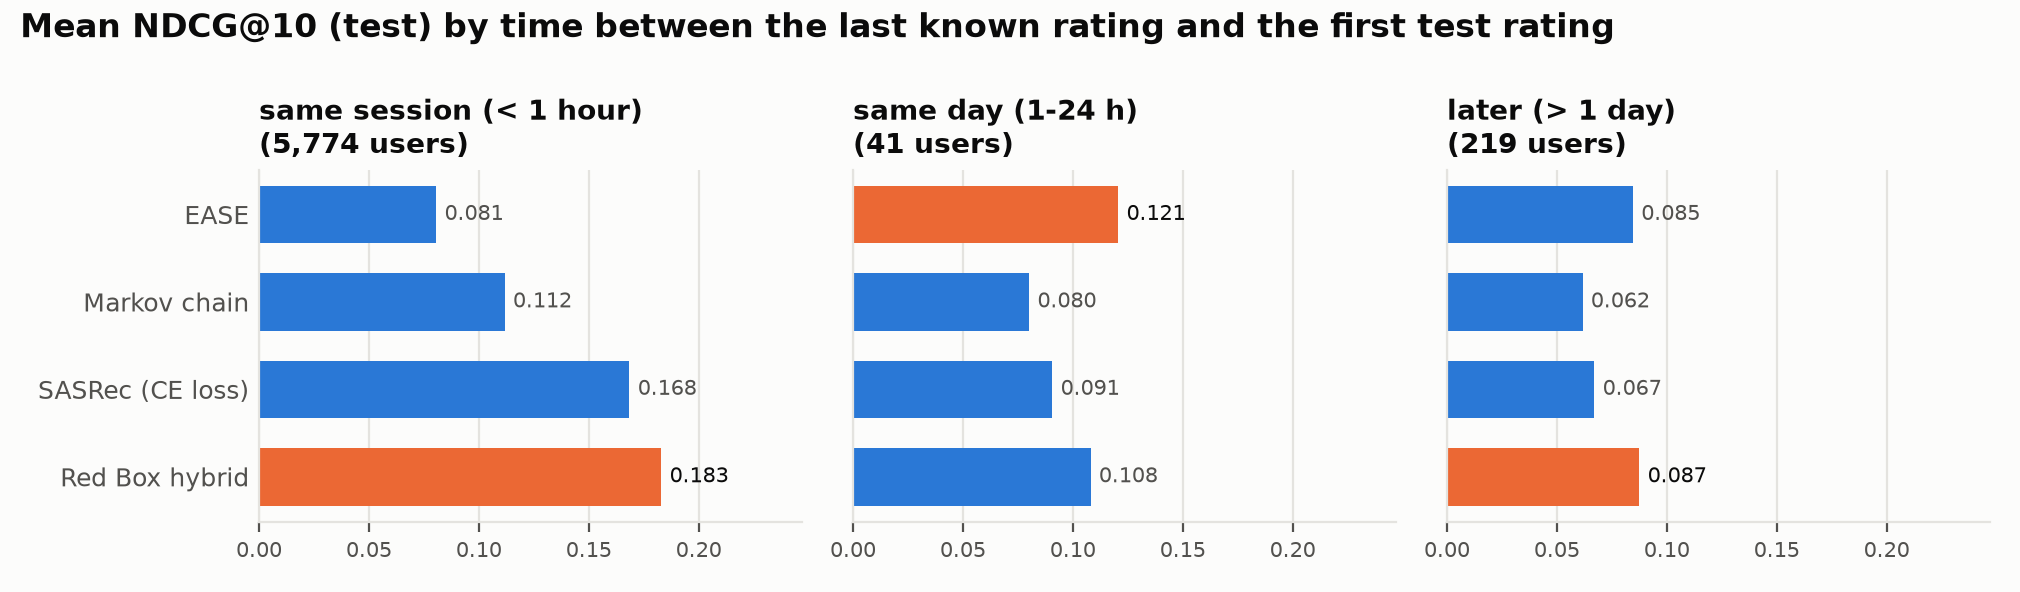

model,EASE,Markov chain,SASRec (CE loss),Red Box hybrid,users
session,,,,,
same session (< 1 hour),0.0806,0.1117,0.1685,0.1830,5774
same day (1-24 h),0.1206,0.0801,0.0906,0.1080,41
later (> 1 day),0.0846,0.0616,0.0670,0.0875,219


In [4]:
session = R.by_session(per_user, split, ["ease", "markov", "sasrec_ce", "hybrid"])
show(R.plot_by_session(session, ["ease", "markov", "sasrec_ce", "hybrid"], FIG / "results_by_session.png"))
session.rename(columns=name).round(4)

In [5]:
ablation_cfg = ExperimentConfig.load("ml-1m-ablations")
shuffled_hash = params_hash(ablation_cfg.models["sasrec_ce_shuffled"])
shuffled = find_run("ml-1m", split.stats["fingerprint"], "sasrec_ce_shuffled", shuffled_hash)
if shuffled is None:
    print("Order ablation not finished yet: re-run after `recsys benchmark -c ml-1m-ablations`.")
else:
    real = test.set_index("model").loc[name("sasrec_ce"), "NDCG@10"]
    print(f"SASRec (CE), real order:     test NDCG@10 {real:.4f}")
    print(f"SASRec (CE), shuffled order: test NDCG@10 {shuffled.data.metrics['test_ndcg_at_10']:.4f}")

SASRec (CE), real order:     test NDCG@10 0.1643
SASRec (CE), shuffled order: test NDCG@10 0.0633


**96% of MovieLens users (5,774 of 6,034) gave their first test rating less than an hour after their last
known rating, in the same rating session.**
- **For those users, SASRec is 2.1× as accurate as EASE** (0.169 vs 0.081).
- **For the 219 users who came back more than a day later, the ranking flips:** EASE (0.085) beats
  SASRec (0.067) and Markov (0.062).

MovieLens users rated movies in bulk on pages the website arranged, so the *order* within a session mostly
reflects how the site displayed movies, not taste (Fan et al., 2023). The sequential models learn that
order, and the order ablation above measures how much of SASRec's score depends on it. The hybrid is the
best system in the two large groups (it relies on the sequence signal within a session and on taste
models otherwise). EASE beats it only in the small same-day group (41 users).

## 4. RQ2: the Red Box hybrid

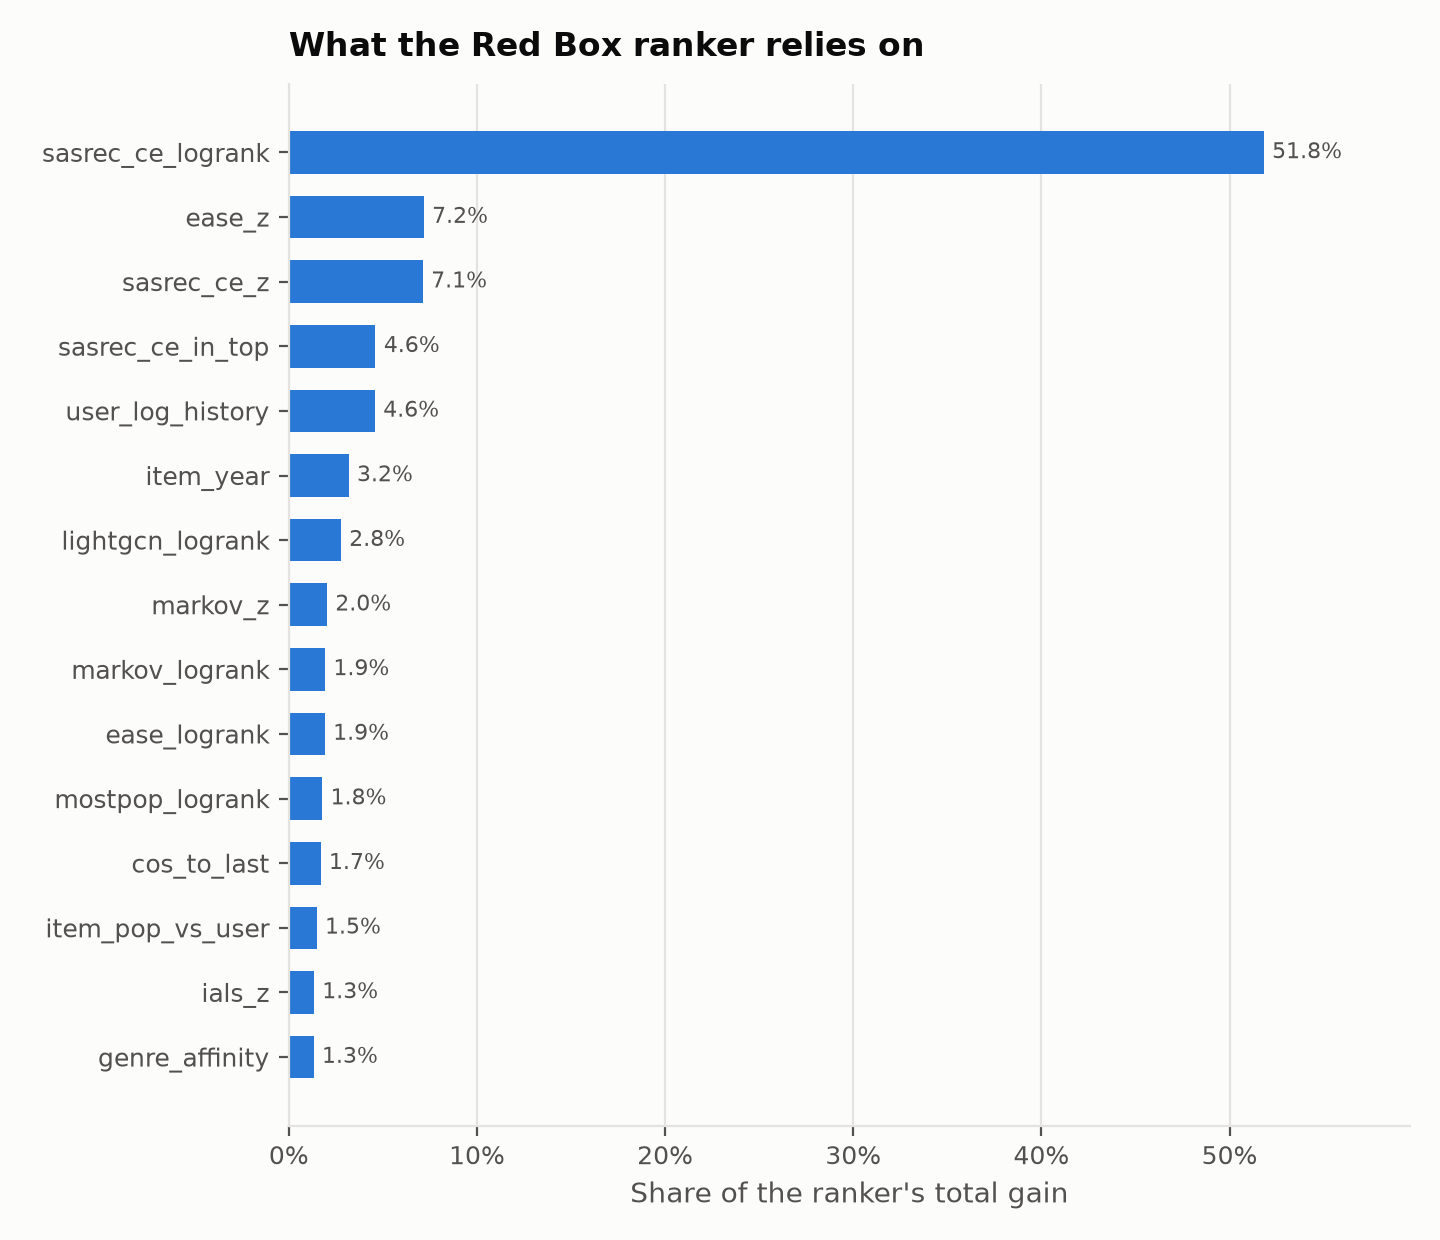

In [6]:
imp = pd.read_csv(results_docs_dir("ml-1m", "hybrid", "feature_importance.csv"), index_col=0).iloc[:, 0]
show(R.plot_feature_importance(imp, FIG / "hybrid_feature_importance.png"))

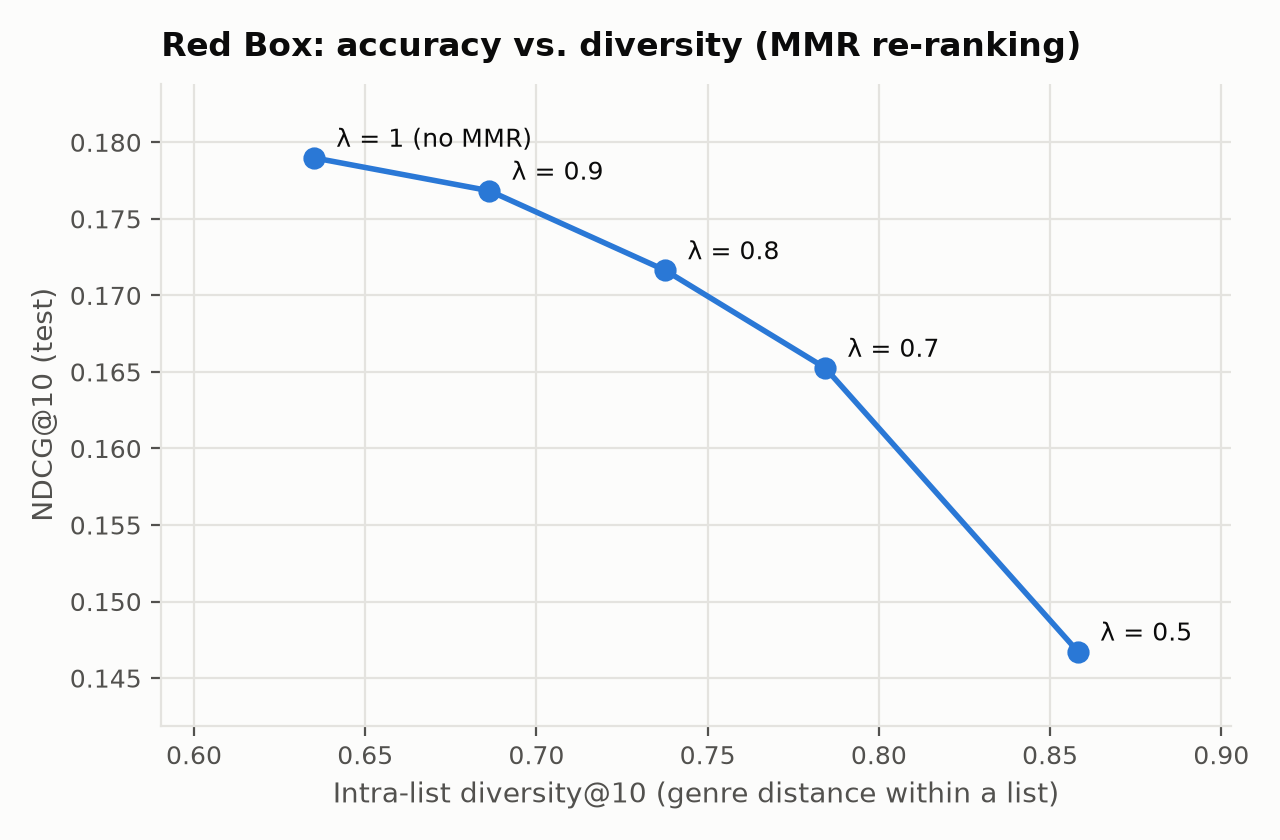

,lam,ndcg,ild,Coverage@10
12,1.0,0.1790,0.6350,0.5315
13,0.9,0.1768,0.6862,0.5220
14,0.8,0.1716,0.7376,0.5110
15,0.7,0.1653,0.7843,0.4997
16,0.5,0.1467,0.8582,0.4803


In [7]:
mmr = test[test.model.str.startswith("Red Box") | test.model.str.startswith("hybrid_mmr")].copy()
mmr["lam"] = [1.0 if m.startswith("Red Box") else float(m.replace("hybrid_mmr", "")) for m in mmr.model]
mmr = mmr.rename(columns={"NDCG@10": "ndcg", "ILD@10": "ild"}).sort_values("lam", ascending=False)
show(R.plot_mmr_tradeoff(mmr, FIG / "hybrid_mmr_tradeoff.png"))
mmr[["lam", "ndcg", "ild", "Coverage@10"]].round(4)

**The hybrid is significantly better than the best single model** (+9.0% NDCG@10 over SASRec, p ≈ 10⁻²⁶).
- **The ranker leans heavily on SASRec's rank** (52% of its total gain), the strongest single signal. EASE's
  taste score (7%), SASRec's score, the user's history length, release year, LightGCN, Markov,
  similarity to the last movie and genre match account for the rest. It learns *when* to trust the
  sequential signal and when to fall back on taste: this is why it beats SASRec for users who return
  after more than a day (section 3).
- **MMR diversity has a smooth, controllable cost.** With λ = 0.8, genre diversity within a list rises
  from 0.64 to 0.74 for −4% NDCG. With λ = 0.5 it reaches 0.86 for −18%. In the app this is the diversity
  slider.

## 5. RQ3: accuracy vs. catalog coverage, and who is served well

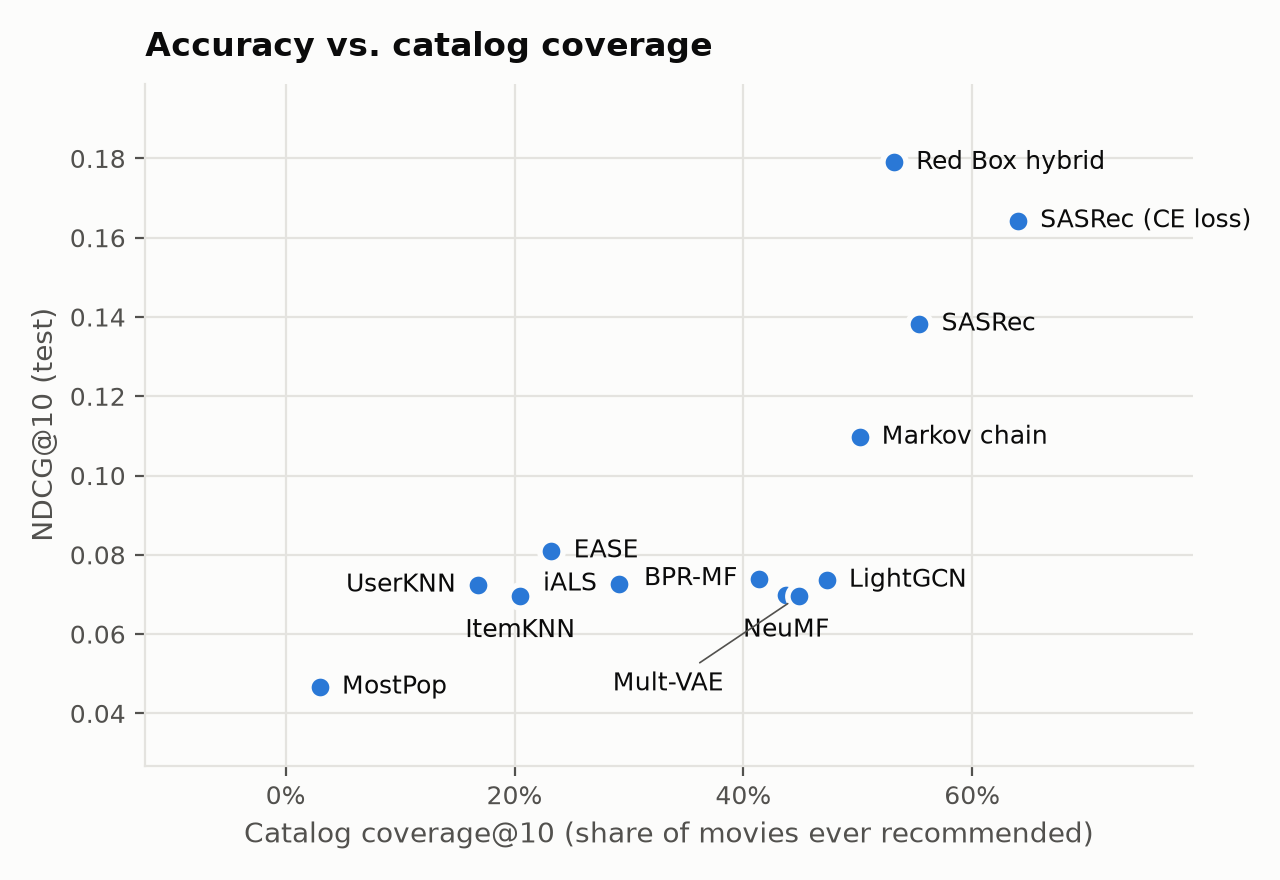

In [8]:
show(
    R.plot_accuracy_vs_coverage(
        test[~test.model.str.startswith("hybrid_mmr")], FIG / "results_accuracy_vs_coverage.png"
    )
)

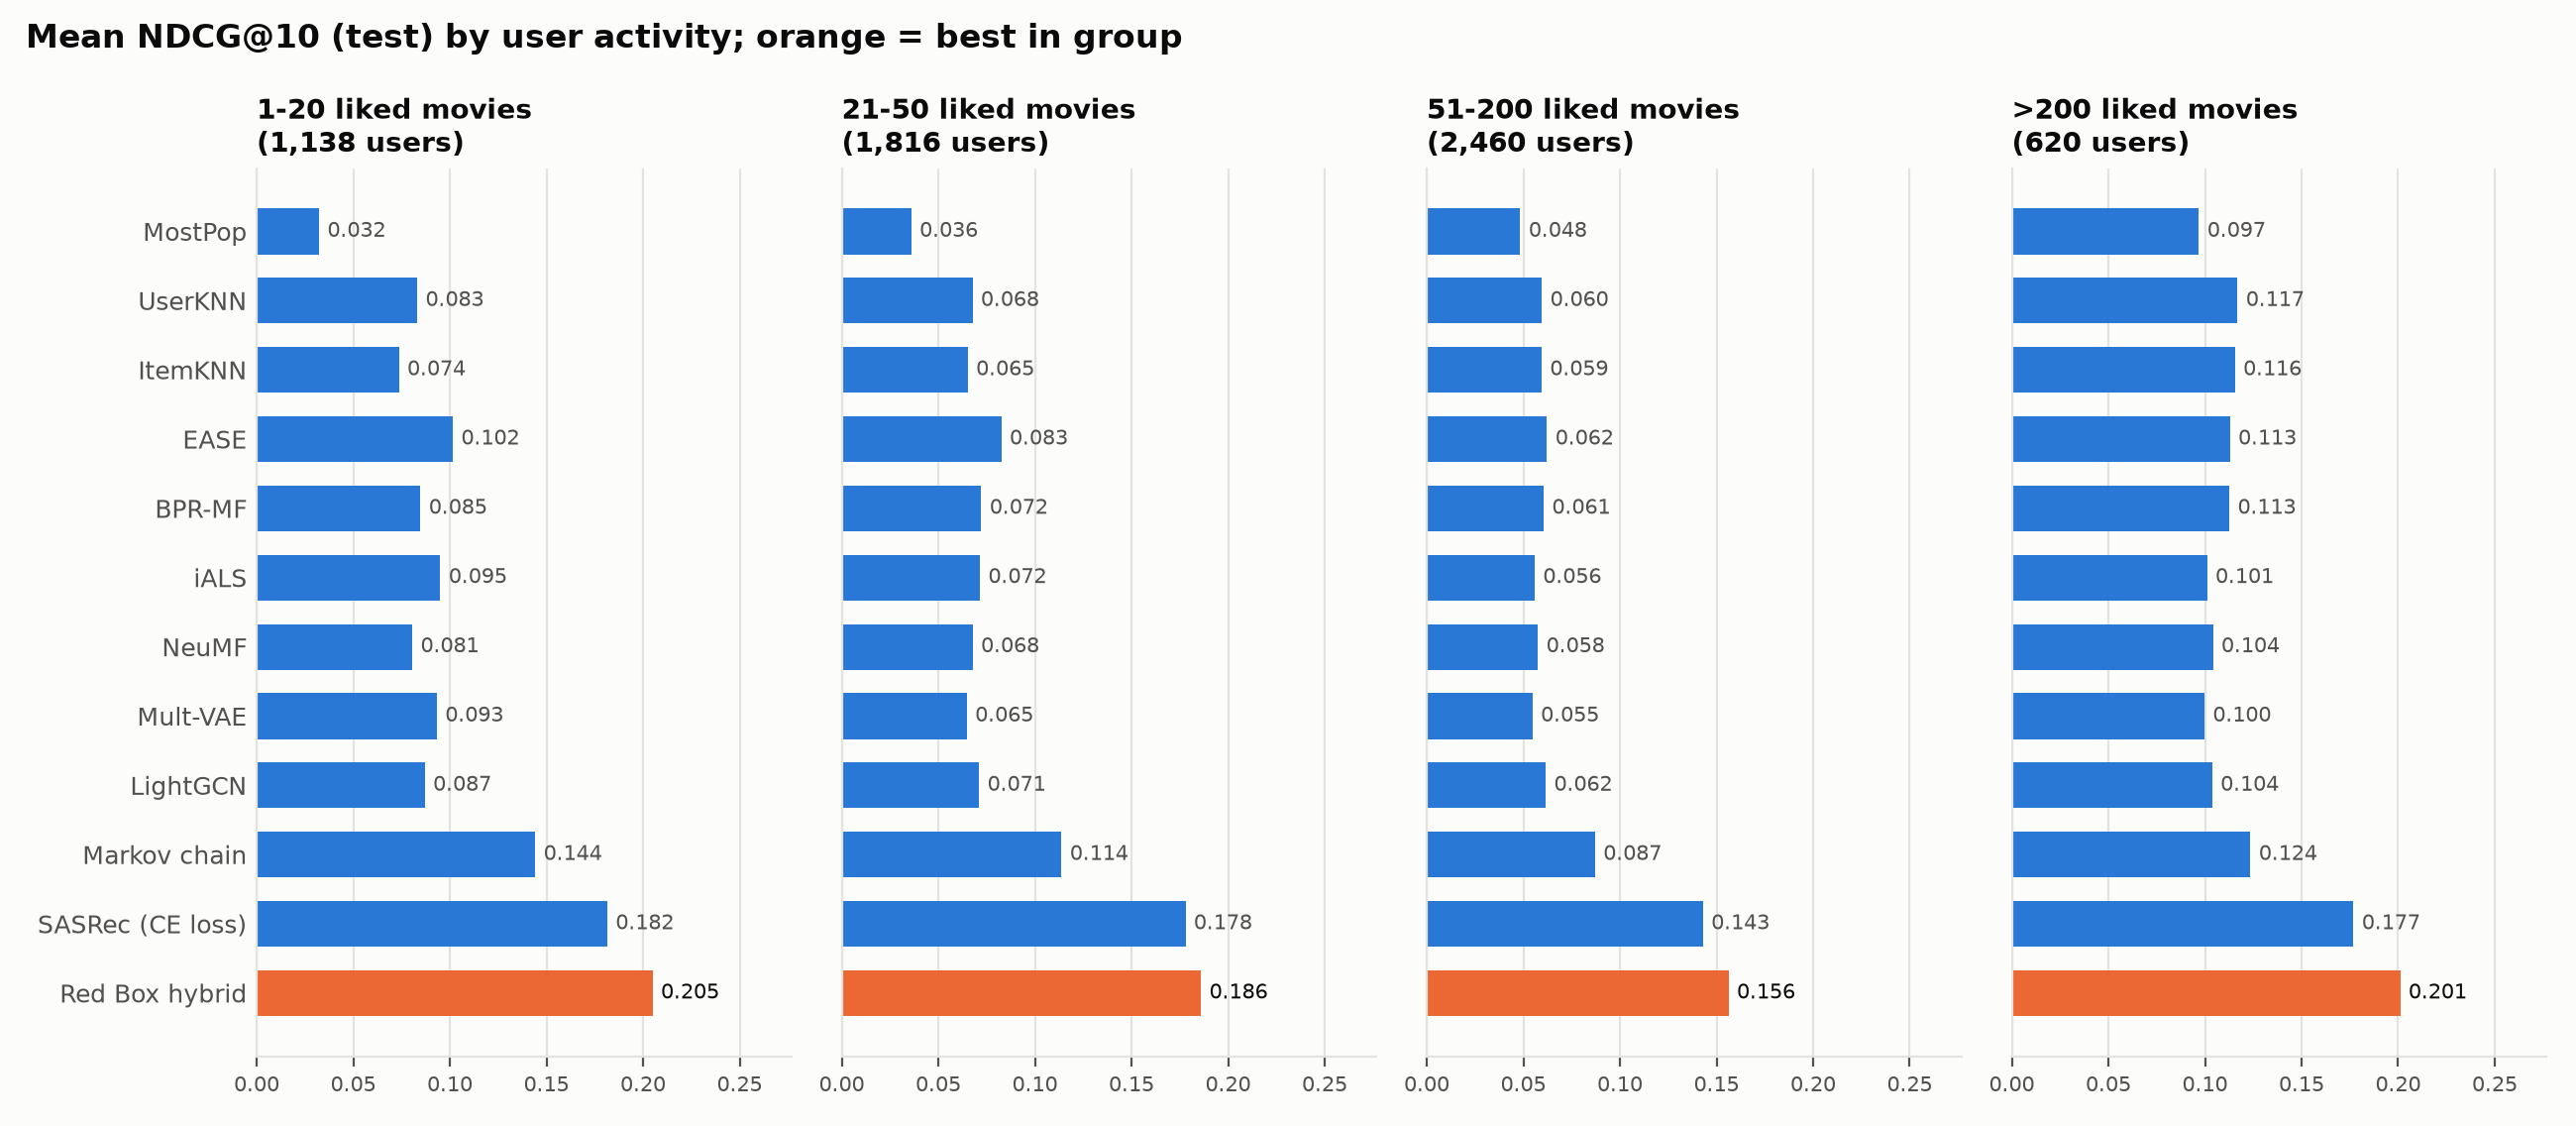

In [9]:
models = [
    "mostpop",
    "userknn",
    "itemknn",
    "ease",
    "bpr",
    "ials",
    "neumf",
    "multvae",
    "lightgcn",
    "markov",
    "sasrec_ce",
    "hybrid",
]
activity = R.by_activity(per_user[per_user.model.isin(models)])
show(R.plot_by_activity(activity, models, FIG / "results_ndcg_by_activity.png"))

## 6. RQ4: does it hold for products? Amazon Video Games

In [10]:
acfg = ExperimentConfig.load("amazon-videogames-tuned")
asplit = load_split(acfg)
amazon = pd.read_csv(results_docs_dir("amazon-videogames", "tuned", "test.csv"))
amazon[["model", "family", "NDCG@10", "Recall@10", "HR@10", "Coverage@10", "Novelty@10"]].sort_values(
    "NDCG@10", ascending=False
).set_index("model").round(4)

,family,NDCG@10,Recall@10,HR@10,Coverage@10,Novelty@10
model,,,,,,
Red Box hybrid,Two-stage hybrid (ours),0.0919,0.1552,0.1653,0.7557,7.6591
SASRec (CE loss),Sequential (Transformer),0.0849,0.1453,0.1547,0.7042,7.8603
EASE,Linear autoencoder,0.0706,0.1221,0.1286,0.7741,7.7090
ItemKNN,Neighbourhood,0.0647,0.1139,0.1195,0.7816,7.7771
UserKNN,Neighbourhood,0.0629,0.1116,0.1174,0.4977,6.9640
Markov chain,Sequential (Markov),0.0618,0.1002,0.1075,0.8115,7.5883
LightGCN,Graph neural network,0.0586,0.1053,0.1107,0.7842,7.7032
iALS,Latent factor,0.0585,0.1049,0.1103,0.2424,7.4863
BPR-MF,Latent factor,0.0321,0.0579,0.0610,0.9816,8.4273


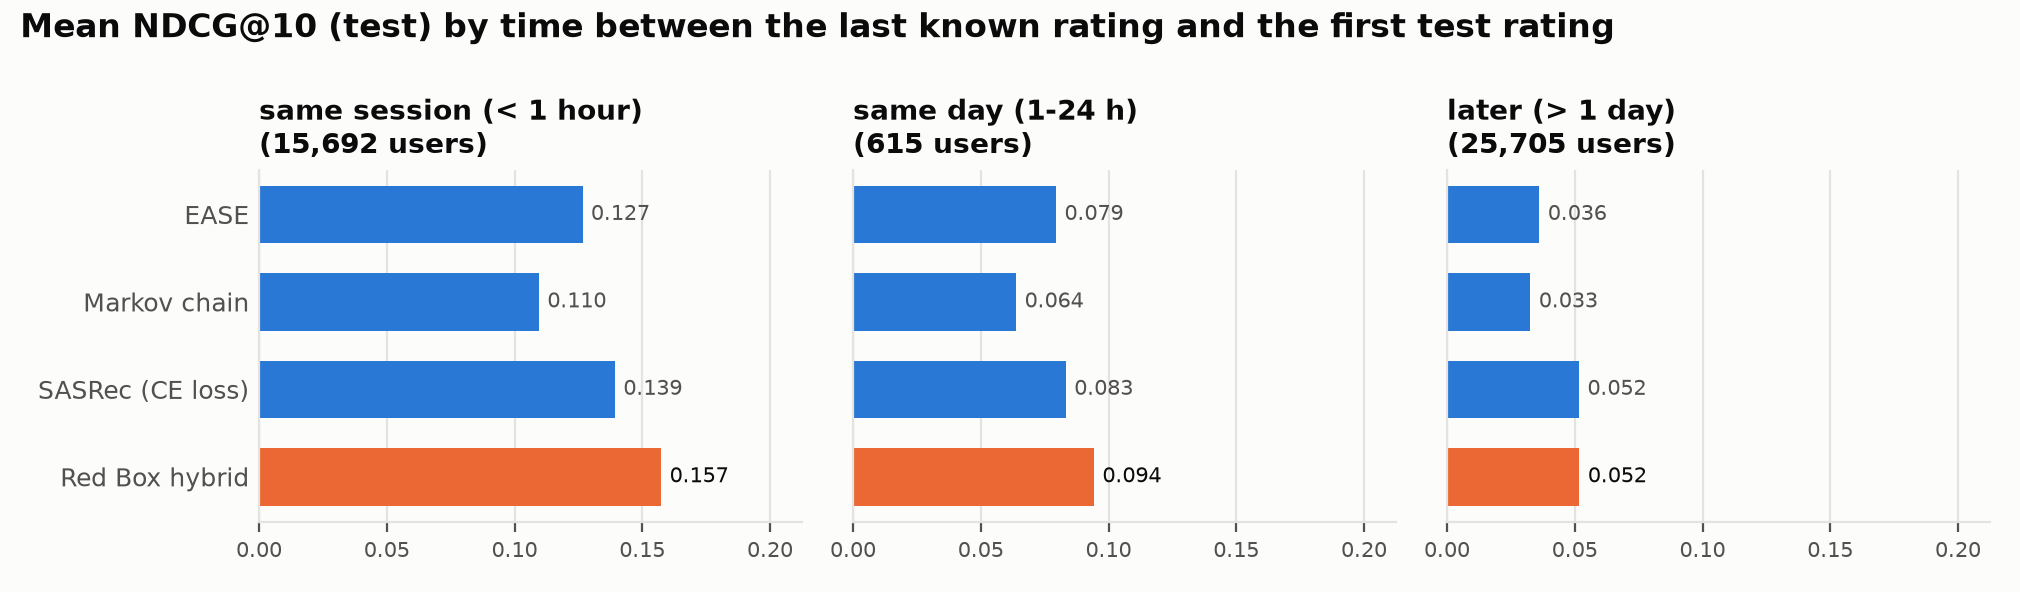

model,EASE,Markov chain,SASRec (CE loss),Red Box hybrid,users
session,,,,,
same session (< 1 hour),0.1266,0.1096,0.1393,0.1574,15692
same day (1-24 h),0.0795,0.0639,0.0833,0.0943,615
later (> 1 day),0.0362,0.0327,0.0517,0.0519,25705


In [11]:
a_user = per_user_from_mlflow(acfg, asplit)
a_session = R.by_session(a_user, asplit, ["ease", "markov", "sasrec_ce", "hybrid"])
show(
    R.plot_by_session(
        a_session,
        ["ease", "markov", "sasrec_ce", "hybrid"],
        figures_dir("results", "amazon-videogames", "results_by_session.png"),
    )
)
a_session.rename(columns=name).round(4)

In [12]:
both = pd.DataFrame(
    {
        "MovieLens-1M": test.set_index("model")["NDCG@10"],
        "Amazon Video Games": amazon.set_index("model")["NDCG@10"],
    }
).dropna()
both["MovieLens rank"] = both["MovieLens-1M"].rank(ascending=False).astype(int)
both["Amazon rank"] = both["Amazon Video Games"].rank(ascending=False).astype(int)
both.sort_values("MovieLens rank").round(4)

,MovieLens-1M,Amazon Video Games,MovieLens rank,Amazon rank
model,,,,
Red Box hybrid,0.1790,0.0919,1,1
SASRec (CE loss),0.1643,0.0849,2,2
Markov chain,0.1097,0.0618,3,6
EASE,0.0810,0.0706,4,3
BPR-MF,0.0740,0.0321,5,9
LightGCN,0.0736,0.0586,6,7
iALS,0.0726,0.0585,7,8
UserKNN,0.0724,0.0629,8,5
ItemKNN,0.0696,0.0647,9,4


**Amazon has no bulk-rating artifact.** Only 0.03% of reviews share a second with another review by the
same user, against 77% on MovieLens. The picture changes accordingly:
- **The Markov chain drops below EASE** (−12%, significant). Its MovieLens advantage came from rating
  sessions.
- **SASRec still beats EASE (+20%), including for users who return days later** (0.052 vs 0.036). Product
  purchases do have a real "what comes next" structure: accessories, sequels, platforms.
- **EASE is again the best non-sequential model**, significantly ahead of LightGCN and iALS (+20% each).
- **The Red Box hybrid is again the best system** (+8.3% over SASRec, p ≈ 10⁻²⁷).

So the core conclusions hold on both datasets: tuned EASE ≥ deep non-sequential models; the hybrid
beats every single model. How large the sequential advantage is depends on how the data was collected.

## 7. What tuning changed (validation vs. test)

In [13]:
default_cfg = ExperimentConfig.load("ml-1m")
fp = split.stats["fingerprint"]
tuned_rows = {r.model: r for r in rows_from_mlflow("ml-1m", report_entries(cfg), fp)}
default_rows = {r.model: r for r in rows_from_mlflow("ml-1m", report_entries(default_cfg), fp)}
changes = []
for m, r in tuned_rows.items():
    d = default_rows.get(m)
    if (
        d is None
        or m.startswith("hybrid")
        or params_hash(cfg.models.get(m, {})) == params_hash(default_cfg.models.get(m, {}))
    ):
        continue
    changes.append({"model": name(m), "val default": d.val["ndcg@10"], "val tuned": r.val["ndcg@10"],
                    "test default": d.test["ndcg@10"], "test tuned": r.test["ndcg@10"]})  # fmt: skip
changes = pd.DataFrame(changes).set_index("model")
changes["test change"] = changes["test tuned"] / changes["test default"] - 1
changes.round(4)

no MLflow run for 'hybrid' (settings 9ae07aba9f8b) on split 8d6a7a5a8a4c83ab; left out


no MLflow run for 'hybrid_mmr0.9' (settings 9ae07aba9f8b) on split 8d6a7a5a8a4c83ab; left out


no MLflow run for 'hybrid_mmr0.8' (settings 9ae07aba9f8b) on split 8d6a7a5a8a4c83ab; left out


no MLflow run for 'hybrid_mmr0.7' (settings 9ae07aba9f8b) on split 8d6a7a5a8a4c83ab; left out


no MLflow run for 'hybrid_mmr0.5' (settings 9ae07aba9f8b) on split 8d6a7a5a8a4c83ab; left out


,val default,val tuned,test default,test tuned,test change
model,,,,,
UserKNN,0.0792,0.0810,0.0727,0.0724,-0.0040
ItemKNN,0.0765,0.0787,0.0709,0.0696,-0.0183
EASE,0.0867,0.0868,0.0810,0.0810,0.0002
BPR-MF,0.0709,0.0801,0.0685,0.0740,0.0797
iALS,0.0730,0.0759,0.0707,0.0726,0.0268
NeuMF,0.0716,0.0734,0.0683,0.0698,0.0208


- **BPR-MF gains most from tuning:** a larger dimension and stronger regularization give +8% on test.
  NeuMF and iALS gain 2–3%.
- **The neighbourhood models improve on validation but are slightly *worse* on test.** That's
  overfitting to the validation period, a reminder of why the test set must be touched only once.
- **EASE's paper default was already optimal.**

## 8. Rating prediction (experiment E7) and training cost

In [14]:
pd.read_csv(results_docs_dir("ml-1m", "rating_prediction", "results.csv")).set_index("model").drop(
    columns="params"
).round(4)

,val_rmse,val_mae,test_rmse,test_mae,fit_seconds
model,,,,,
Global mean,1.1291,0.9302,1.1620,0.9588,0.0054
User + item biases,0.9165,0.7222,0.9272,0.7307,0.5243
Biased MF (SVD),0.8574,0.6706,0.8634,0.6751,95.2953


In [15]:
R.training_costs("ml-1m", [m for m in models if m != "hybrid"], fp).round(1)

,fit on train (s),refit on train+val (s),epochs (best),test scoring (s)
model,,,,
MostPop,0.0,0.0,NaN,0.4
UserKNN,0.0,0.0,NaN,2.1
ItemKNN,0.7,0.8,NaN,1.5
EASE,1.9,1.8,NaN,1.0
BPR-MF,447.1,420.0,120.0,0.4
iALS,13.0,6.4,5.0,0.4
NeuMF,682.1,307.0,12.0,17.8
Mult-VAE,826.1,474.4,105.0,2.2
LightGCN,2440.3,2684.0,360.0,0.5


## Summary for the report

| Question | Answer |
|---|---|
| RQ1: do deep models beat well-tuned classic CF? | Not the non-sequential ones: tuned EASE significantly beats LightGCN, NeuMF, Mult-VAE, iALS and BPR-MF on both datasets. The sequential Transformer (SASRec) does win. |
| RQ2: does the hybrid beat the best single model? | Yes, on both datasets: +9.0% (MovieLens) and +8.3% (Amazon) NDCG@10 over SASRec, highly significant |
| RQ3: accuracy vs. diversity, and which users? | MMR gives a smooth trade-off (+16% diversity for −4% accuracy at λ = 0.8). On MovieLens, sequential models win inside rating sessions and taste models (EASE) for users who return later |
| RQ4: does it hold for products? | The main conclusions hold. The Markov chain's MovieLens advantage disappears on Amazon, revealing a data-collection artifact |
| Rating prediction (E7) | Biased MF: RMSE 0.863, against 0.927 for user + item biases and 1.162 for the global mean |